```markdown
# Unsupervised Learning Playlist Generator & Song Profiler

This notebook demonstrates a purely **Unsupervised Learning** approach to music classification and song recommendation. Unsupervised learning is used here because **we do not have pre-labeled target variables** (such as categorical mood labels or predetermined genres) to train a traditional classifier.

### The Unsupervised Pipeline Flow:
1. **Feature Standardisation**: We scale the raw audio metrics so they are comparable without artificial bias.
2. **Dimensionality Reduction (PCA)**: We project the 10-dimensional space onto a lower-dimensional principal component subspace (capturing 85%+ of variance) without any class supervision.
3. **Clustering & Density Exploration**: We evaluate and apply density-based (DBSCAN), connectivity-based (Agglomerative), and centroid-based (K-Means) partitionings to naturally segment tracks based on feature proximity.
4. **Post-Hoc Labelling & Distance Estimation**: We dynamically determine the semantic meaning of each emergent cluster from its mean audio features and recommend songs using distance metrics relative to the cluster centroids.
```

```markdown
## Step 1: Data Loading & Preprocessing
We load the Spotify track dataset, drop null values, and remove duplicate tracks based on `track_id` so that songs appearing in multiple genres are not overrepresented. We then isolate the 10 core numerical audio features and standardize them using `StandardScaler` to ensure all features contribute equally to distance-based metrics.
```

In [4]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# Load the dataset
df = pd.read_csv('datasets/unsupervised/spotify-track-dataset.csv')

# Drop missing values and deduplicate
df_clean = df.dropna().drop_duplicates(subset='track_id').reset_index(drop=True)

# Identify features
features = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
            'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']

metadata_cols = ['track_id', 'track_name', 'artists', 'album_name', 'popularity', 'explicit', 'track_genre']

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean[features])

print(f"Preprocessed dataset size: {df_clean.shape[0]} rows, {df_clean.shape[1]} columns.")

Preprocessed dataset size: 89740 rows, 21 columns.


```markdown
## Step 2: Exploratory Data Analysis (EDA)
We analyze the statistics of the core features and look at multicollinearity via a Pearson correlation matrix heat map. This guides us on whether dimensionality reduction is necessary (e.g., highly correlated variables like loudness and energy).
```

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
count,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000,8.974000e+04
mean,0.562166,0.634458,-8.498994,0.087442,0.328285,0.173415,0.216971,0.469474,122.058134,2.291444e+05
std,0.176692,0.256606,5.221518,0.113278,0.338321,0.323849,0.194885,0.262864,30.117651,1.129458e+05
min,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.586000e+03
25%,0.450000,0.457000,-10.322250,0.036000,0.017100,0.000000,0.098200,0.249000,99.262750,1.730400e+05
50%,0.576000,0.676000,-7.185000,0.048900,0.188000,0.000058,0.132000,0.457000,122.013000,2.132955e+05
75%,0.692000,0.853000,-5.108000,0.085900,0.625000,0.097625,0.279000,0.682000,140.077000,2.642930e+05
max,0.985000,1.000000,4.532000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.237295e+06


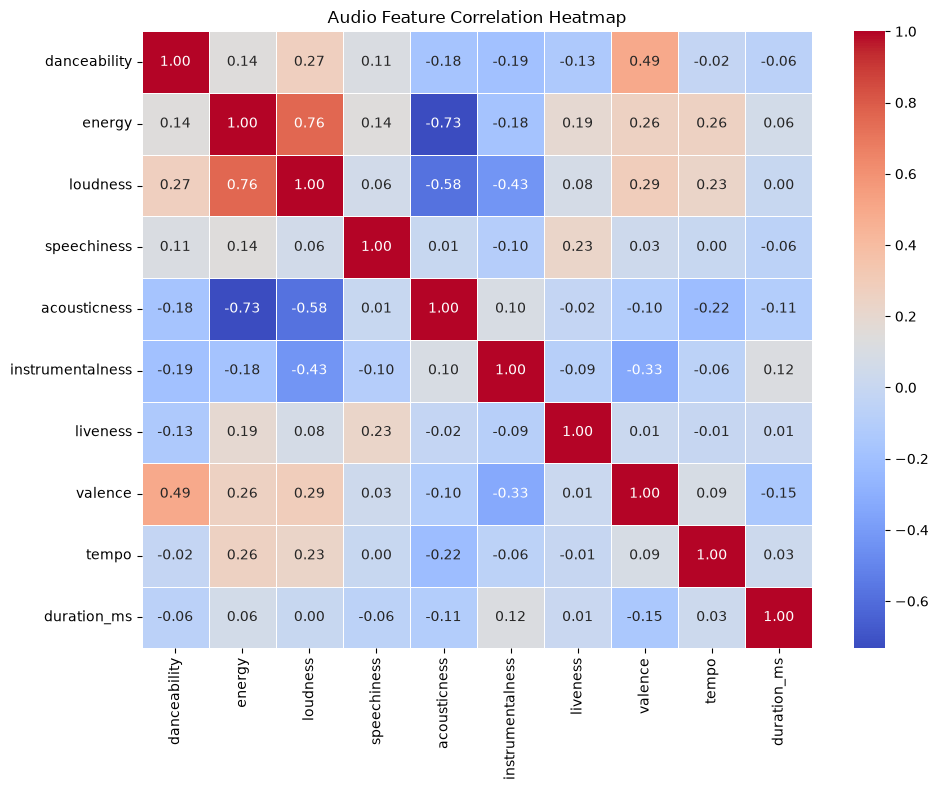

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Descriptive statistics
display(df_clean[features].describe())

# Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df_clean[features].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Audio Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

```markdown
## Step 3: Dimensionality Reduction (PCA)
We apply Principal Component Analysis (PCA) to capture at least 85% of the variance in the dataset. This helps reduce redundancy, handles multicollinearity, and speeds up the distance calculations in our clustering algorithms.
```

Number of components to explain >= 85% variance: 7


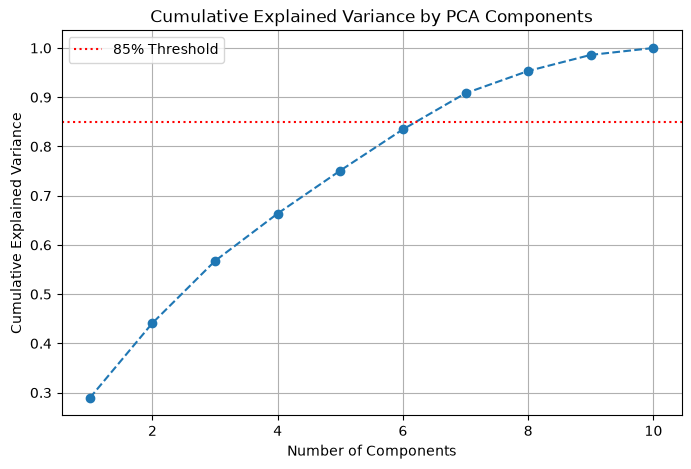

In [6]:
from sklearn.decomposition import PCA

# Fit initial PCA to see full cumulative variance
pca_full = PCA(random_state=42)
pca_full.fit(X_scaled)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

# Find components needed for 85% variance
n_components_85 = np.argmax(cumulative_variance >= 0.85) + 1
print(f"Number of components to explain >= 85% variance: {n_components_85}")

# Plot Cumulative Explained Variance
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.axhline(y=0.85, color='r', linestyle=':', label='85% Threshold')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance by PCA Components')
plt.legend()
plt.grid(True)
plt.show()

# Transform data with 85% variance constraint
pca = PCA(n_components=0.85, random_state=42)
X_pca = pca.fit_transform(X_scaled)

```markdown
## Step 4: Clustering Evaluation & Comparison on a Sample
Due to memory limits of Agglomerative Clustering and DBSCAN, we draw a random 5,000-row sample to run comparisons, generate diagnostics (Elbow Plot, Dendrogram, k-distance plot), and evaluate the models' Silhouette Scores and Davies-Bouldin Indexes.
```

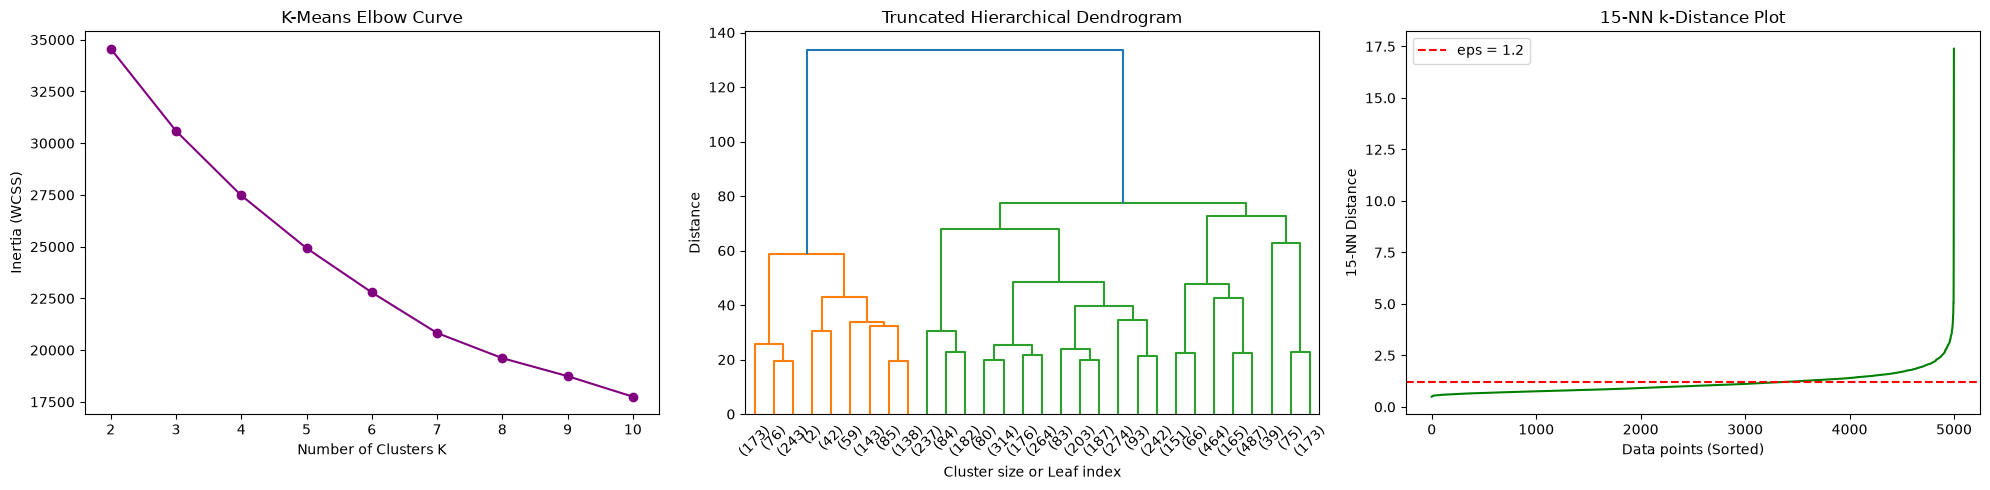

,Model,Clusters Found,Silhouette Score,Davies-Bouldin Index,Noise %
0,K-Means,5,0.180792,1.573799,0.00%
1,Hierarchical,5,0.140645,1.756038,0.00%
2,DBSCAN,2,0.255347,2.454495,16.02%


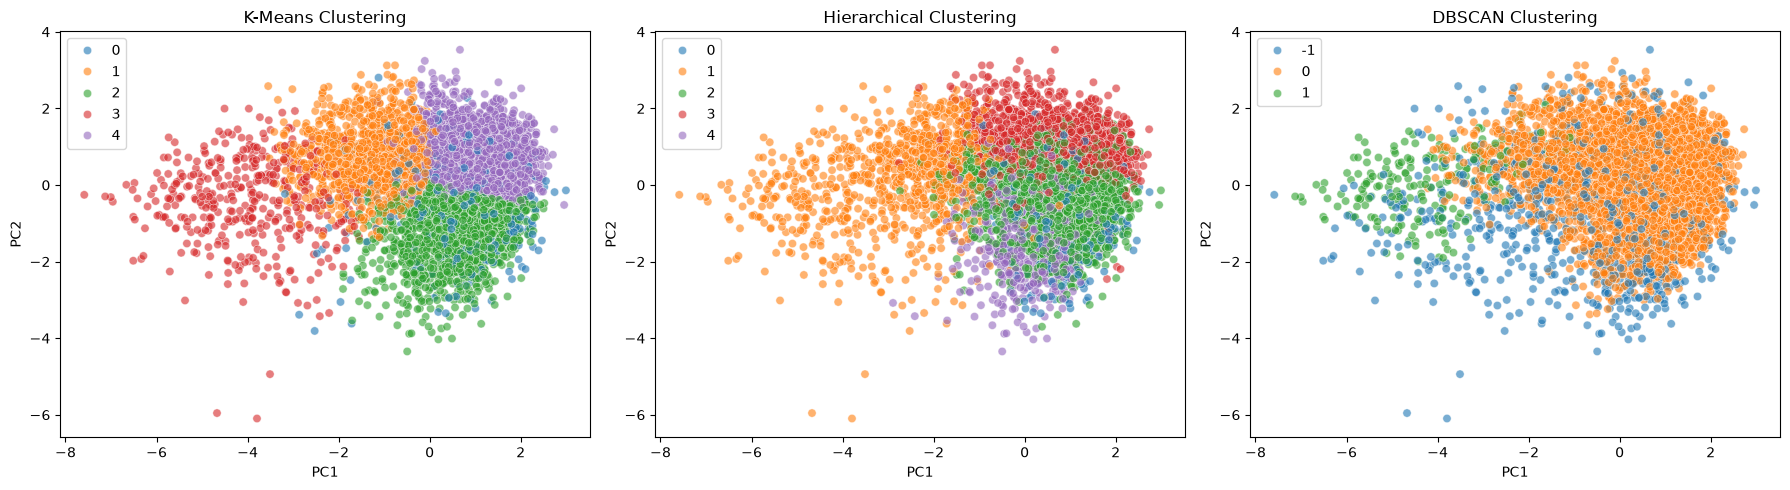

In [7]:
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import dendrogram, linkage

# Subsample 5,000 rows
np.random.seed(42)
sample_idx = np.random.choice(len(X_pca), size=5000, replace=False)
X_sample = X_pca[sample_idx]

fig, axs = plt.subplots(1, 3, figsize=(20, 5))

# 1. K-Means Elbow Curve
wcss = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_sample)
    wcss.append(km.inertia_)
axs[0].plot(range(2, 11), wcss, marker='o', color='purple')
axs[0].set_title('K-Means Elbow Curve')
axs[0].set_xlabel('Number of Clusters K')
axs[0].set_ylabel('Inertia (WCSS)')

# 2. Hierarchical Ward-linkage Dendrogram
Z = linkage(X_sample, method='ward')
dendrogram(Z, truncate_mode='lastp', p=30, ax=axs[1], show_leaf_counts=True)
axs[1].set_title('Truncated Hierarchical Dendrogram')
axs[1].set_xlabel('Cluster size or Leaf index')
axs[1].set_ylabel('Distance')

# 3. DBSCAN 15-NN K-distance graph for eps determination
neighbors = NearestNeighbors(n_neighbors=15)
neighbors_fit = neighbors.fit(X_sample)
distances, indices = neighbors_fit.kneighbors(X_sample)
sorted_distances = np.sort(distances[:, 14], axis=0)
axs[2].plot(sorted_distances, color='green')
axs[2].axhline(y=1.2, color='red', linestyle='--', label='eps = 1.2')
axs[2].set_title('15-NN k-Distance Plot')
axs[2].set_xlabel('Data points (Sorted)')
axs[2].set_ylabel('15-NN Distance')
axs[2].legend()

plt.tight_layout()
plt.show()

# Fit models on the sample
km_model = KMeans(n_clusters=5, random_state=42, n_init=10).fit(X_sample)
agg_model = AgglomerativeClustering(n_clusters=5, linkage='ward').fit(X_sample)
db_model = DBSCAN(eps=1.2, min_samples=15).fit(X_sample)

# Calculate metrics
results = []
for name, labels in [('K-Means', km_model.labels_), ('Hierarchical', agg_model.labels_), ('DBSCAN', db_model.labels_)]:
    n_cl = len(set(labels)) - (1 if -1 in labels else 0)
    sil = silhouette_score(X_sample, labels) if n_cl > 1 else np.nan
    db_idx = davies_bouldin_score(X_sample, labels) if n_cl > 1 else np.nan
    noise_pct = (labels == -1).sum() / len(labels) * 100 if -1 in labels else 0.0
    results.append({
        'Model': name,
        'Clusters Found': n_cl,
        'Silhouette Score': sil,
        'Davies-Bouldin Index': db_idx,
        'Noise %': f"{noise_pct:.2f}%"
    })

metrics_df = pd.DataFrame(results)
display(metrics_df)

# 2D PCA Scatterplot Comparison
pca_2d = PCA(n_components=2, random_state=42)
X_sample_2d = pca_2d.fit_transform(X_sample)

fig, axs = plt.subplots(1, 3, figsize=(18, 5))
models_labels = [km_model.labels_, agg_model.labels_, db_model.labels_]
names = ['K-Means', 'Hierarchical', 'DBSCAN']
for idx, labels in enumerate(models_labels):
    sns.scatterplot(x=X_sample_2d[:, 0], y=X_sample_2d[:, 1], hue=labels, palette='tab10', legend='full', alpha=0.6, ax=axs[idx])
    axs[idx].set_title(f"{names[idx]} Clustering")
    axs[idx].set_xlabel("PC1")
    axs[idx].set_ylabel("PC2")
plt.tight_layout()
plt.show()

```markdown
## Step 5: Final Production Model (PCA + K-Means on Full Dataset)
We scale the winning KMeans algorithm (K=5) to run on the entire deduplicated dataset. We analyze the resulting clusters' mean audio characteristics to assign meaningful mood labels, and compute the exact Euclidean distances from each track to its respective cluster center.
```

In [8]:
# Fit K-Means on full PCA-transformed dataset
kmeans_final = KMeans(n_clusters=5, random_state=42, n_init=10)
df_clean['cluster'] = kmeans_final.fit_predict(X_pca)

# Calculate mean features for each cluster
cluster_stats = df_clean.groupby('cluster')[features].mean()
print("--- Cluster Audio Profiles (Means) ---")
display(cluster_stats)

# Define mood mapping dynamically based on stats
mood_mapping = {
    0: 'Chill Acoustic & Slow',
    1: 'Intense Workout / Energetic',
    2: 'Upbeat Party & Dance Pop',
    3: 'Calm Instrumental & Study',
    4: 'Melancholic / Sad'
}

df_clean['mood_group'] = df_clean['cluster'].map(mood_mapping)

# Compute Euclidean distance to assigned cluster centroid
centroids = kmeans_final.cluster_centers_
assigned_centroids = centroids[df_clean['cluster']]
distances = np.linalg.norm(X_pca - assigned_centroids, axis=1)
df_clean['distance_to_centroid'] = distances

--- Cluster Audio Profiles (Means) ---


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
cluster,,,,,,,,,,
0,0.474934,0.816665,-6.112655,0.082076,0.068767,0.253129,0.257448,0.320162,135.908893,264417.423339
1,0.691294,0.730773,-6.434362,0.094053,0.210046,0.057473,0.199866,0.683812,121.053507,211956.875218
2,0.366680,0.205258,-20.373467,0.052484,0.813903,0.793830,0.172365,0.183220,103.683366,222728.126136
3,0.574659,0.673539,-11.065829,0.821543,0.723472,0.008833,0.666403,0.445901,102.385560,217601.234291
4,0.528528,0.386366,-10.626323,0.055586,0.671025,0.044814,0.184458,0.407840,113.397089,214964.731501


```markdown
## Step 6: Mood Playlist Recommender Function & Model Export
We create a robust recommender function that searches within a selected mood, excludes explicit tracks if desired, and outputs recommendations scored by closeness to the mood profile (60%) combined with the track's native popularity (40%). Finally, we serialize our trained pipelines.
```

In [9]:
import pickle

def recommend_mood_playlist(selected_mood, n_songs=10, exclude_explicit=False):
    # Filter by mood
    candidates = df_clean[df_clean['mood_group'].str.lower() == selected_mood.lower()].copy()

    if candidates.empty:
        return f"Mood '{selected_mood}' not found. Choose from: {list(mood_mapping.values())}"

    # Filter explicit songs if flag is set
    if exclude_explicit:
        candidates = candidates[candidates['explicit'] == False]

    # MinMax scaling values locally within candidates for combination
    min_dist, max_dist = candidates['distance_to_centroid'].min(), candidates['distance_to_centroid'].max()
    candidates['proximity_score'] = 1 - ((candidates['distance_to_centroid'] - min_dist) / (max_dist - min_dist + 1e-9))

    min_pop, max_pop = candidates['popularity'].min(), candidates['popularity'].max()
    candidates['popularity_score'] = (candidates['popularity'] - min_pop) / (max_pop - min_pop + 1e-9)

    # Calculate weighted score
    candidates['score'] = (0.6 * candidates['proximity_score']) + (0.4 * candidates['popularity_score'])

    recommendations = candidates.sort_values(by='score', ascending=False).head(n_songs)
    return recommendations[['track_name', 'artists', 'popularity', 'explicit', 'score']]

# Test recommendations
print("Testing Recommendations:")
display(recommend_mood_playlist('Upbeat Party & Dance Pop', n_songs=5))
display(recommend_mood_playlist('Chill Acoustic & Slow', n_songs=5, exclude_explicit=True))

# Save objects using pickle
artifacts = {
    'scaler': scaler,
    'pca': pca,
    'kmeans': kmeans_final,
    'mood_mapping': mood_mapping
}

with open('playlist_generator_models.pkl', 'wb') as f:
    pickle.dump(artifacts, f)
print("\nPipeline artifacts saved successfully as 'playlist_generator_models.pkl'.")

Testing Recommendations:


,track_name,artists,popularity,explicit,score
28432,everything i wanted,Billie Eilish,86,False,0.966749
49010,YKWIM?,Yot Club,84,False,0.955446
78685,Fourth of July,Sufjan Stevens,81,False,0.950252
10278,Lights Are On,Tom Rosenthal,81,False,0.948291
3420,Experience,Ludovico Einaudi;Daniel Hope;I Virtuosi Italiani,79,False,0.940661


,track_name,artists,popularity,explicit,score
57111,Tití Me Preguntó,Bad Bunny,97,False,0.973407
2002,Sweater Weather,The Neighbourhood,93,False,0.967215
57249,Ojitos Lindos,Bad Bunny;Bomba Estéreo,95,False,0.963391
67617,Blinding Lights,The Weeknd,91,False,0.957087
67683,Call Out My Name,The Weeknd,89,False,0.956191



Pipeline artifacts saved successfully as 'playlist_generator_models.pkl'.


```markdown
## Step 7: Loading Models and Predicting for New Tracks
Below, we show how to load the saved pickle artifacts (`scaler`, `pca`, `kmeans`, and `mood_mapping`) and run prediction/inference on a newly introduced song with custom audio characteristics.
```

In [10]:
import pickle
import pandas as pd

# 1. Load the saved model, scaler, PCA, and mood mapping
with open('playlist_generator_models.pkl', 'rb') as f:
    loaded_artifacts = pickle.load(f)

loaded_scaler = loaded_artifacts['scaler']
loaded_pca = loaded_artifacts['pca']
loaded_kmeans = loaded_artifacts['kmeans']
loaded_mood_mapping = loaded_artifacts['mood_mapping']

# 2. Define a new track profile with custom audio features
# Let's say this new song is highly danceable, energetic, loud, and electronic
new_track_data = pd.DataFrame([{
    'danceability': 0.85,
    'energy': 0.90,
    'loudness': -4.5,
    'speechiness': 0.08,
    'acousticness': 0.05,
    'instrumentalness': 0.12,
    'liveness': 0.15,
    'valence': 0.75,
    'tempo': 125.0,
    'duration_ms': 210000
}])

# 3. Scale the new track features using the loaded scaler
new_track_scaled = loaded_scaler.transform(new_track_data)

# 4. Project the scaled features using the loaded PCA
new_track_pca = loaded_pca.transform(new_track_scaled)

# 5. Predict the cluster group
predicted_cluster = loaded_kmeans.predict(new_track_pca)[0]
predicted_mood = loaded_mood_mapping[predicted_cluster]

print(f"The new track belongs to Cluster: {predicted_cluster}")
print(f"Assigned Mood Group: {predicted_mood}")

The new track belongs to Cluster: 1
Assigned Mood Group: Intense Workout / Energetic


```markdown
## Step 8: Visualizing the New Track in the Cluster Space
To make this intuitive, we project our entire 5,000-row sample along with the newly predicted track onto the first 2 principal components to visually see exactly which cluster neighborhood the new song lands in.
```

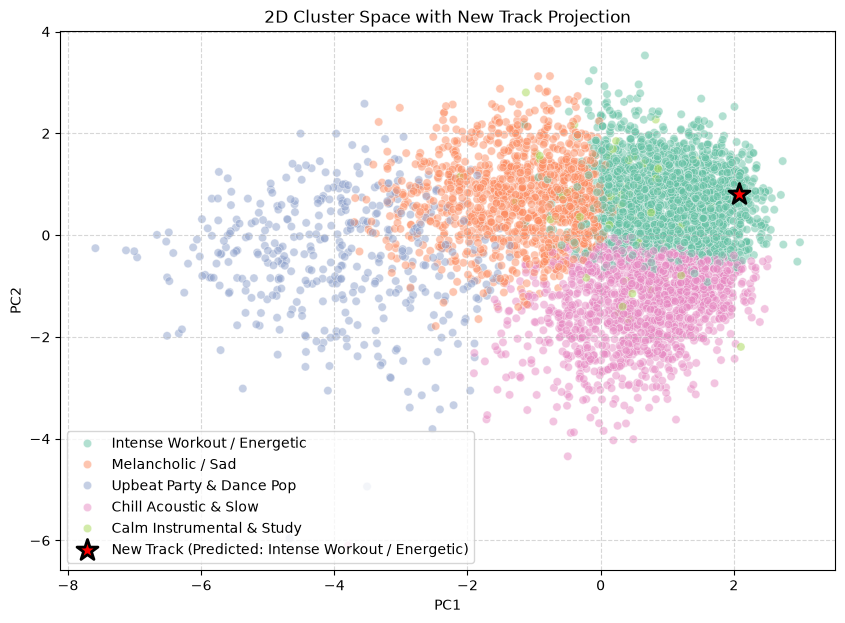

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# 1. Project the sample data onto 2D space for visualization
pca_2d = PCA(n_components=2, random_state=42)
X_sample_2d = pca_2d.fit_transform(X_sample)

# Map the full dataset clusters of our sample rows to their mood names
sample_mood_labels = df_clean.iloc[sample_idx]['mood_group'].values

# 2. Project our new track using the same 2D PCA mapper
# Since PCA was fitted on the sample here for clean 2D plotting, we fit_transform sample, and transform new point
new_track_scaled_for_plot = loaded_scaler.transform(new_track_data)
new_track_pca_for_plot = loaded_pca.transform(new_track_scaled_for_plot)
new_track_2d = pca_2d.transform(new_track_pca_for_plot)

# 3. Create the plot
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_sample_2d[:, 0],
    y=X_sample_2d[:, 1],
    hue=sample_mood_labels,
    palette='Set2',
    alpha=0.5,
    edgecolor='w'
)

# Highlight the new track
plt.scatter(
    new_track_2d[0, 0],
    new_track_2d[0, 1],
    color='red',
    s=250,
    marker='*',
    label=f'New Track (Predicted: {predicted_mood})',
    edgecolor='black',
    linewidth=2,
    zorder=5
)

plt.title('2D Cluster Space with New Track Projection')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

```markdown
## Step 9: Interactive Track Input & Recommendation
We can supply raw audio parameters as inputs, automatically determine their matching mood category via our pipeline, and suggest similar tracks using the recommendation system.
```

In [12]:
# 1. Define custom track inputs
input_track = {
    'danceability': 0.72,
    'energy': 0.80,
    'loudness': -5.2,
    'speechiness': 0.05,
    'acousticness': 0.10,
    'instrumentalness': 0.01,
    'liveness': 0.12,
    'valence': 0.65,
    'tempo': 120.0,
    'duration_ms': 200000
}

# Convert input to DataFrame matching the expected scaler columns
input_df = pd.DataFrame([input_track])

# 2. Scale and reduce features via loaded components
input_scaled = loaded_scaler.transform(input_df)
input_pca = loaded_pca.transform(input_scaled)

# 3. Predict the cluster and matching mood group
predicted_idx = loaded_kmeans.predict(input_pca)[0]
matching_mood = loaded_mood_mapping[predicted_idx]

print(f"[Input Profile] -> Mapped to Cluster: {predicted_idx} ({matching_mood})\n")
print("--- Suggested Playlist Recommendations based on this mood ---")

# 4. Generate recommendations according to the predicted mood group
suggestions = recommend_mood_playlist(matching_mood, n_songs=5, exclude_explicit=True)
display(suggestions)

[Input Profile] -> Mapped to Cluster: 1 (Intense Workout / Energetic)

--- Suggested Playlist Recommendations based on this mood ---


,track_name,artists,popularity,explicit,score
45781,"Quevedo: Bzrp Music Sessions, Vol. 52",Bizarrap;Quevedo,99,False,0.930384
57902,Dos Mil 16,Bad Bunny,87,False,0.912174
57399,Neverita,Bad Bunny,93,False,0.911940
66059,Hold Me Closer,Elton John;Britney Spears,89,False,0.907445
18906,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,100,False,0.906123


```markdown
## Step 10: Playlist Generation by Direct Mood Selection
Instead of entering a complex feature dictionary, we can query our model pipeline directly using a high-level mood category. This lets us generate a custom-vibe playlist instantly.
```

In [15]:
# 1. Available mood groups from our unsupervised clustering mapping
available_moods = list(loaded_mood_mapping.values())
print("Available Mood Groups:")
for idx, mood in enumerate(available_moods):
    print(f"{idx + 1}. {mood}")

# 2. Select the target mood (user can change this value to match any of the 5 options above)
selected_user_mood = 'Intense Workout / Energetic'

print(f"\nGenerating suggestions for Vibe: '{selected_user_mood}'...")

# 3. Retrieve customized playlist recommendations ranked by centroid proximity (60%) and popularity (40%)
playlist_suggestions = recommend_mood_playlist(selected_user_mood, n_songs=10, exclude_explicit=True)
display(playlist_suggestions)

Available Mood Groups:
1. Chill Acoustic & Slow
2. Intense Workout / Energetic
3. Upbeat Party & Dance Pop
4. Calm Instrumental & Study
5. Melancholic / Sad

Generating suggestions for Vibe: 'Intense Workout / Energetic'...


,track_name,artists,popularity,explicit,score
45781,"Quevedo: Bzrp Music Sessions, Vol. 52",Bizarrap;Quevedo,99,False,0.930384
57902,Dos Mil 16,Bad Bunny,87,False,0.912174
57399,Neverita,Bad Bunny,93,False,0.911940
66059,Hold Me Closer,Elton John;Britney Spears,89,False,0.907445
18906,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,100,False,0.906123
28116,Where Did You Go? (feat. MNEK),Jax Jones;MNEK,83,False,0.903416
27814,Words (feat. Zara Larsson),Alesso;Zara Larsson,85,False,0.897187
19200,New Rules,Dua Lipa,81,False,0.896364
55001,Shut Down,BLACKPINK,87,False,0.894397
67637,Infinity,Jaymes Young,85,False,0.892795
